**VISUAL MASK**

In [5]:
import digitalhub as dh

NOME_PROGETTO = "floods"
project = dh.get_project(NOME_PROGETTO)
print(f"Progetto: {project.name}")

Progetto: floods


**SETUP PARAMETERS**

In [28]:
# Parametri Job   
job_name = "v1"                                
                                 
parametri = {
    "input_artifact": "Floods_Anomalies_v3_crop_norm",
    "stats_name": "Floods_Anomalies_v4_crop_norm_stats",   
    "output_name": "Floods_Anomalies_v4_crop_norm",
    "tile": 128,
    "max_part_gb": 15.0,
    "max_series": 0,
    "min_flood_pct": 1,
    "max_per_event": 0,
    "seed": 0,
}                                                         

# volume -> circa 400 GB dataset Standard
volumi = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",      
        "spec": {"size": "400Gi"}   
    }
]

**BUILD ENVIRONMENT**

In [29]:
test_train_func = project.new_function(
    name= f'split_128_{job_name}',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../src/", 
    handler="utils:split_tiles_artifact", 
    base_image="pytorch/pytorch:2.1.2-cuda11.8-cudnn8-runtime",
    requirements=["pandas==2.3.3", "numpy==1.26.4", "rasterio==1.4.4", "tqdm==4.70.0", "tifffile==2024.8.30", "torch==2.1.2", "matplotlib==3.10.9", "digitalhub==0.15.11", "digitalhub-runtime-python==0.15.2", "zarr==2.18.0", "numcodecs==0.13.1", "xarray==2025.6.1"]
)

# .run("build") -> scarica immagine, installa requirements, copia intera cartella code_src, crea immagine docker

build = test_train_func.run("build", wait=True)
print(f"BUILD: {build.status.state}")

2026-10-16 13:30:20,539 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b1146c4820844e5db59747c657b94705 to finish...
2026-10-16 13:30:25,545 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b1146c4820844e5db59747c657b94705 to finish...
2026-10-16 13:30:30,553 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b1146c4820844e5db59747c657b94705 to finish...
2026-10-16 13:30:35,560 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b1146c4820844e5db59747c657b94705 to finish...
2026-10-16 13:30:40,569 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b1146c4820844e5db59747c657b94705 to finish...
2026-10-16 13:30:45,577 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b1146c4820844e5db59747c657b94705 to finish...
2026-10-16 13:30:50,585 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run b1146c4820844e5db59747c657b94705 to finish...
2026-10-16 13

BUILD: COMPLETED


**TRAINING**

In [30]:
# action job = avvia container, esegue script, libera risorse

run_test_encoders = test_train_func.run(
    action="job", 
    parameters=parametri, 
    volumes=volumi, 
    profile="cpu-shared",                                       # 1x = 1 gpu
    # local_execution= True,                                
    wait=True
)

print(f"Run test_encoders avviato: {run_test_encoders.id}")
print(run_test_encoders.status.state)
print(run_test_encoders.status.message)

2026-10-16 13:31:20,901 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f82588e3274348a5a82e5fe6dde46ea3 to finish...
2026-10-16 13:31:25,907 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f82588e3274348a5a82e5fe6dde46ea3 to finish...
2026-10-16 13:31:30,915 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f82588e3274348a5a82e5fe6dde46ea3 to finish...
2026-10-16 13:31:35,923 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f82588e3274348a5a82e5fe6dde46ea3 to finish...
2026-10-16 13:31:40,931 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f82588e3274348a5a82e5fe6dde46ea3 to finish...
2026-10-16 13:31:45,939 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f82588e3274348a5a82e5fe6dde46ea3 to finish...
2026-10-16 13:31:50,948 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run f82588e3274348a5a82e5fe6dde46ea3 to finish...
2026-10-16 13

Run test_encoders avviato: f82588e3274348a5a82e5fe6dde46ea3
COMPLETED
None


In [31]:
import os
import pandas as pd
import matplotlib.pyplot as plt

project_data = dh.get_project("datasets")          # il CSV e' stato caricato nel progetto "datasets"

csv_path = project_data.get_artifact(parametri["stats_name"]).download("./tiles_stats", overwrite=True)
if os.path.isdir(csv_path):                         # se l'artifact e' una cartella, cerco il csv dentro
    csv_path = [os.path.join(dp, f) for dp, _, fs in os.walk(csv_path) for f in fs if f.endswith(".csv")][0]

df = pd.read_csv(csv_path)
df["evento"] = df["ID"].str.split("_").str[0]       # evento = codice EMSR, prima parte dell'ID
print(f"{len(df)} serie nel CSV, {df['evento'].nunique()} eventi")

9608 serie nel CSV, 63 eventi


In [32]:
min_flood_pct = 1     # tiene le serie con flood_pct >= questo valore
max_per_event = 0     # tetto di serie per evento; 0 = nessun tetto

soglia flood:          1%
tetto per evento:      nessuno (0 eventi tagliati)
SERIE TOTALI:          7828
EVENTI:                63
evento piu' grande:    EMSR629 = 953 (12.2%)
primi 5 eventi:        38.0%
primi 10 eventi:       58.9%
mediana per evento:    55
eventi con <= 5 serie: 9


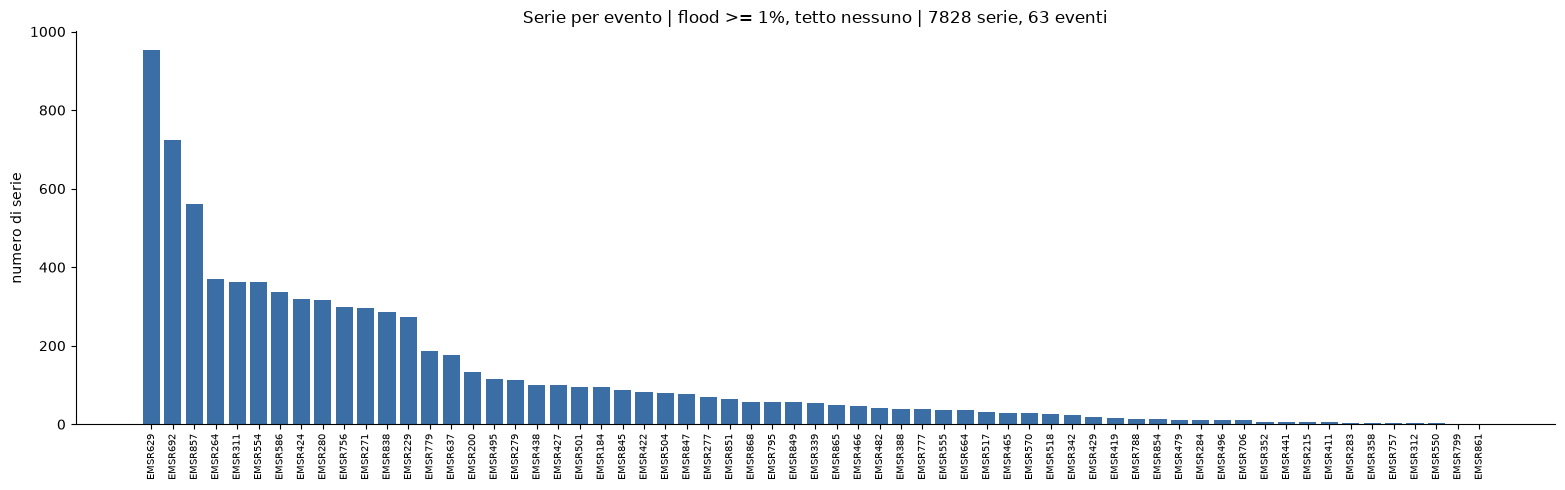

In [33]:
sel = df[df["flood_pct"] >= min_flood_pct]
counts_raw = sel["evento"].value_counts()

counts = counts_raw.clip(upper=max_per_event) if max_per_event > 0 else counts_raw
counts = counts.sort_values(ascending=False)
tot = int(counts.sum())
tetto = max_per_event if max_per_event > 0 else "nessuno"

print(f"soglia flood:          {min_flood_pct}%")
print(f"tetto per evento:      {tetto} ({int((counts_raw > max_per_event).sum()) if max_per_event > 0 else 0} eventi tagliati)")
print(f"SERIE TOTALI:          {tot}")
print(f"EVENTI:                {len(counts)}")
print(f"evento piu' grande:    {counts.index[0]} = {counts.iloc[0]} ({100 * counts.iloc[0] / tot:.1f}%)")
print(f"primi 5 eventi:        {100 * counts.head(5).sum() / tot:.1f}%")
print(f"primi 10 eventi:       {100 * counts.head(10).sum() / tot:.1f}%")
print(f"mediana per evento:    {int(counts.median())}")
print(f"eventi con <= 5 serie: {int((counts <= 5).sum())}")

fig, ax = plt.subplots(figsize=(max(10, 0.25 * len(counts)), 5))
ax.bar(range(len(counts)), counts.values, color="#3b6ea5")
if max_per_event > 0:
    ax.axhline(max_per_event, color="#c0392b", linestyle="--", linewidth=1, label=f"tetto = {max_per_event}")
    ax.legend()
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(counts.index, rotation=90, fontsize=7)
ax.set_ylabel("numero di serie")
ax.set_title(f"Serie per evento | flood >= {min_flood_pct}%, tetto {tetto} | {tot} serie, {len(counts)} eventi")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()